# 01 - Data Understanding

**Phase 1.** Before writing any cleaning code, understand what the raw data
actually contains and whether it can answer the business question.

**Business question:** *Which customers should the company prioritise for retention, and why?*

To answer it the dataset must have: identifiable customers, repeat purchases,
and enough time span to observe behaviour and then check what happened next.
This notebook tests each of those.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
import config
from data_processing import load_raw, profile

## 1. Load the raw data

The UCI Online Retail workbook: one row per invoice line.

In [2]:
raw = load_raw()
print(f'{raw.shape[0]:,} rows x {raw.shape[1]} columns')
raw.head()

541,909 rows x 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Column profile

What is in each column, and what is missing?

In [3]:
profile(raw)

,dtype,non_null,missing,missing_pct,unique
InvoiceNo,object,541909,0,0.00,25900
StockCode,object,541909,0,0.00,4070
Description,object,540455,1454,0.27,4223
Quantity,int64,541909,0,0.00,722
InvoiceDate,datetime64[ns],541909,0,0.00,23260
UnitPrice,float64,541909,0,0.00,1630
CustomerID,float64,406829,135080,24.93,4372
Country,object,541909,0,0.00,38


### What this shows

* `CustomerID` is missing on a quarter of rows. Those lines cannot be attributed
  to anyone, so they are unusable for customer-level analysis.
* `Description` has a few missing values, which usually signals an adjustment row
  rather than a real sale.
* Everything else is complete.

## 3. Time span

A retention model needs history to learn from **and** a later period to check against.

first transaction: 2010-12-01 08:26:00
last  transaction: 2011-12-09 12:50:00
span: 373 days


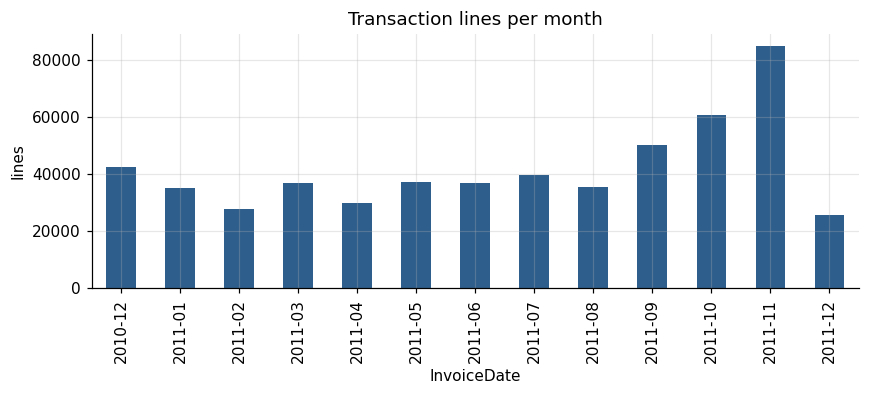

In [4]:
print('first transaction:', raw.InvoiceDate.min())
print('last  transaction:', raw.InvoiceDate.max())
print('span:', (raw.InvoiceDate.max() - raw.InvoiceDate.min()).days, 'days')

monthly = raw.groupby(raw.InvoiceDate.dt.to_period('M')).size()
ax = monthly.plot(kind='bar', figsize=(9, 3), color='#2E5E8C')
ax.set_title('Transaction lines per month'); ax.set_ylabel('lines'); plt.show()

13 months of data. That is enough for the design used later: a 180-day
observation window to build features from, followed by a 90-day window to see
whether the customer came back.

Note the sharp rise from September to November - this is a gift retailer heading
into Christmas. That seasonality is important and is revisited when the model is
evaluated.

## 4. Cancellations and returns

Invoice numbers beginning with `C` are cancellations.

In [5]:
cancel = raw.InvoiceNo.astype(str).str.startswith('C')
print(f'cancellation lines: {cancel.sum():,} ({cancel.mean()*100:.2f}% of rows)')
print(f'customers who ever cancelled: {raw.loc[cancel, "CustomerID"].nunique():,}')
raw[cancel].head(3)

cancellation lines: 9,288 (1.71% of rows)
customers who ever cancelled: 1,589


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom


Cancellations are only 1.7% of rows, but 1,589 customers have at least one.
Rather than simply deleting them, the project keeps them: *how often a customer
cancels* is behaviour, and it becomes a model feature.

## 5. Data quality problems

In [6]:
print(f'exact duplicate rows : {raw.duplicated().sum():,}')
print(f'quantity <= 0        : {(raw.Quantity <= 0).sum():,}')
print(f'unit price <= 0      : {(raw.UnitPrice <= 0).sum():,}')

neg = raw[(raw.Quantity < 0) & ~cancel]
print(f'\nnegative quantity that is NOT a cancellation: {len(neg):,} rows')
print(f'  ...of which missing CustomerID: {neg.CustomerID.isna().sum():,}')
print('\ntypical descriptions on those rows:')
print(neg.Description.fillna('<missing>').value_counts().head(6))

exact duplicate rows : 5,268
quantity <= 0        : 10,624
unit price <= 0      : 2,517

negative quantity that is NOT a cancellation: 1,336 rows
  ...of which missing CustomerID: 1,336

typical descriptions on those rows:
Description
<missing>                862
check                    120
damages                   45
damaged                   42
?                         41
sold as set on dotcom     20
Name: count, dtype: int64


Every non-cancellation negative-quantity row has no `CustomerID`, and the
descriptions (`damages`, `check`, `thrown away`, `?`) confirm these are warehouse
stock adjustments, not customer activity. They drop out naturally once rows
without a customer are excluded.

## 6. Non-product stock codes

In [7]:
sc = raw.StockCode.astype(str).str.upper()
print(sc[~sc.str.match(r'^\d{5}')].value_counts().head(12))

StockCode
POST            1256
DOT              710
M                572
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
DCGSSBOY          11
GIFT_0001_20      10
Name: count, dtype: int64


Some stock codes are not products: `BANK CHARGES`, `AMAZONFEE`, `D` (discount),
`M` (manual), `S` (samples), `B` (bad debt), `CRUK` (charity donation).
These are removed.

Postage codes (`POST`, `DOT`, `C2`) are **kept** - they are genuine charges the
customer paid on a real order.

## 7. The decisive test: is there repeat behaviour to model?

A retention project is pointless if nobody buys twice.

In [8]:
valid = raw[raw.CustomerID.notna() & ~cancel & (raw.Quantity > 0) & (raw.UnitPrice > 0)]
orders = valid.groupby('CustomerID').InvoiceNo.nunique()

print(f'customers                 : {len(orders):,}')
print(f'repeat customers (2+)     : {(orders >= 2).sum():,}  ({(orders >= 2).mean()*100:.1f}%)')
print(f'customers with 3+ orders  : {(orders >= 3).sum():,}')
print(f'median orders per customer: {orders.median():.0f}')

customers                 : 4,338
repeat customers (2+)     : 2,845  (65.6%)
customers with 3+ orders  : 2,010
median orders per customer: 2


## 8. Can a time-based target be built?

Split at a cut-off date: do customers seen before it come back after it?

In [9]:
cut = pd.Timestamp('2011-09-09')
obs = set(valid[valid.InvoiceDate < cut].CustomerID)
fut = set(valid[valid.InvoiceDate >= cut].CustomerID)
returned = obs & fut

print(f'customers active before {cut.date()}: {len(obs):,}')
print(f'  came back afterwards            : {len(returned):,} ({len(returned)/len(obs)*100:.1f}%)')
print(f'  did NOT come back (target = 1)  : {len(obs)-len(returned):,} ({(1-len(returned)/len(obs))*100:.1f}%)')

customers active before 2011-09-09: 3,362
  came back afterwards            : 1,921 (57.1%)
  did NOT come back (target = 1)  : 1,441 (42.9%)


## Verdict

The dataset **is suitable**:

| Requirement | Result |
|---|---|
| Identifiable customers | 4,338 after basic filtering |
| Repeat purchasing | 65.6% buy more than once |
| Enough time span | 373 days |
| A learnable target | ~43% do not return in the next 90 days - well balanced |

No substitute dataset is needed. Proceed to cleaning.

**One caveat to carry forward:** the data is from a UK-based online gift
retailer, and the last quarter is the Christmas peak. Seasonality will affect
how the model's results are read.